# 01 · First models: what explains views?

**Question:** where views are known (TikTok, YouTube, X), how well do followers, engagement, text, our labels and time predict `log10(views)`, and which of them matter?

**Setup:** 5-fold CV grouped by brand (a brand is never in train and test), metric = MAE on log10 views (0.3 = typical factor of 2 off), CI = brand-cluster bootstrap. Code: `src/modeling.py`. Importance is association, not cause.

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu
import modeling as mo

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.2f}".format); pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None); pd.set_option("display.max_colwidth", 90)

In [2]:
f, meta = mo.load_features(ROOT)
print(meta.platform.value_counts().rename(eu.NAMES).to_string())

platform
TikTok         2491
YouTube        2441
X (Twitter)    1803


## 1 · Model ladder
Baselines first (median, constant × followers = Brand24's idea, Brand24 reach as-is), then a gradient model with feature groups added one by one.

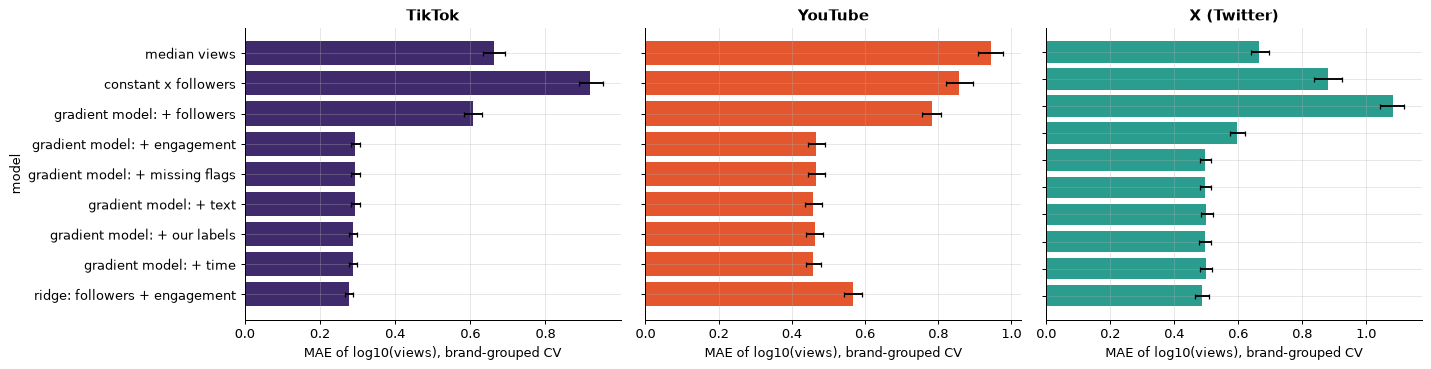

In [3]:
res = pd.concat([mo.ladder(f, meta, p) for p in mo.PLATS], ignore_index=True)
mo.plot_ladder(res)

In [4]:
res.pivot(index='model', columns='platform', values='MAE').reindex(res.model.unique()).round(2)

platform,TikTok,X (Twitter),YouTube
model,,,
median views,0.66,0.67,0.94
constant x followers,0.92,0.88,0.86
gradient model: + followers,0.61,0.60,0.78
gradient model: + engagement,0.29,0.50,0.47
gradient model: + missing flags,0.29,0.50,0.47
gradient model: + text,0.29,0.50,0.46
gradient model: + our labels,0.29,0.50,0.46
gradient model: + time,0.29,0.50,0.46
ridge: followers + engagement,0.28,0.49,0.57


## 2 · Which feature groups matter?
Shuffle one group at a time in the full model on held-out brands; a bigger rise in error means the model relies on it more.

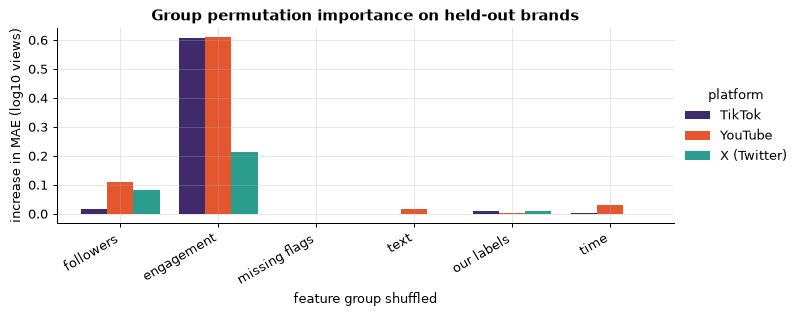

,TikTok,YouTube,X (Twitter)
followers,0.02,0.11,0.08
engagement,0.61,0.61,0.21
missing flags,0.00,0.00,0.00
text,-0.00,0.02,-0.00
our labels,0.01,0.00,0.01
time,0.00,0.03,0.00


In [5]:
imp = pd.concat([mo.importance(f, meta, p) for p in mo.PLATS], axis=1)
mo.plot_importance(imp)
imp.round(3)

## Takeaways

- **Engagement explains most of it.** With likes, comments and shares, the error falls from 0.61 to 0.29 (TikTok), 0.78 to 0.47 (YouTube), 0.60 to 0.50 (X). Shuffling the engagement group raises the error by 0.61 on TikTok and YouTube and 0.21 on X.
- **Followers help little once engagement is known** (importance 0.02-0.11). The constant × followers rule is the worst model here (MAE 0.86-0.92, worse than guessing the median on TikTok and X). Brand24's reach on X is off by 1.08 on average, about a factor of 12.
- **Text, our labels, missing flags and time add nothing measurable** (changes of 0.00-0.03, inside the noise). Mention type and sentiment do not explain views once engagement is in the model.
- **A plain ridge on followers + engagement is nearly as good as the gradient model** on TikTok (0.28 vs 0.29) and X (0.49 vs 0.50), so a simple log-log model is the honest baseline to report.
- **Caveats:** one run, no tuning, no prediction intervals yet. Engagement and views come from the same post at the same time, so this is prediction, not cause. Facebook and Instagram have engagement but no views, so applying these models there is a transfer that cannot be checked directly.